## Bike_Sharing_Demand_Analysis

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("hour.csv")

In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.shape

(17379, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [7]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['dteday'] = pd.to_datetime(df['dteday'])
print(df['dteday'].dtype)

datetime64[ns]


In [16]:
categorical_columns = ['season', 'yr', 'mnth', 'hr', 'holiday',
    'weekday', 'workingday', 'weathersit']
for col in categorical_columns:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))


season:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

yr:
[np.int64(0), np.int64(1)]

mnth:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

hr:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

holiday:
[np.int64(0), np.int64(1)]

weekday:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

workingday:
[np.int64(0), np.int64(1)]

weathersit:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [17]:
df.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,dteady
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088,2012-01-02 04:08:34.552045568
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2011-01-01 00:00:00
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,2011-07-04 00:00:00
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,2012-01-02 00:00:00
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,2012-07-02 00:00:00
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000,2012-12-31 00:00:00
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599,NaN


In [18]:
df['cnt'].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

In [19]:
df.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'hr',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt',
 'dteady']

In [20]:
df['dteday'].equals(df['dteady'])

True

In [21]:
df.drop(columns=['dteady'], inplace=True)

In [22]:
df.shape

(17379, 17)

In [23]:
print("Total Bike Rentals:", df['cnt'].sum())
print("Average Bike Rentals:", df['cnt'].mean())
print("Minimum Bike Rentals:", df['cnt'].min())
print("Maximum Bike Rentals:", df['cnt'].max())

Total Bike Rentals: 3292679
Average Bike Rentals: 189.46308763450142
Minimum Bike Rentals: 1
Maximum Bike Rentals: 977


In [24]:
print("Total Casual Users:", df['casual'].sum())
print("Total Registered Users:", df['registered'].sum())

Total Casual Users: 620017
Total Registered Users: 2672662


In [25]:
hourly_demand = df.groupby('hr')['cnt'].mean().sort_values(ascending=False)
print(hourly_demand)

hr
17    461.452055
18    425.510989
8     359.011004
16    311.983562
19    311.523352
13    253.661180
12    253.315934
15    251.233196
14    240.949246
20    226.030220
9     219.309491
7     212.064649
11    208.143054
10    173.668501
21    172.314560
22    131.335165
23     87.831044
6      76.044138
0      53.898072
1      33.375691
2      22.869930
5      19.889819
3      11.727403
4       6.352941
Name: cnt, dtype: float64


In [26]:
print("Highest Demand Hour:", hourly_demand.idxmax())
print("Lowest Demand Hour:", hourly_demand.idxmin())

Highest Demand Hour: 17
Lowest Demand Hour: 4


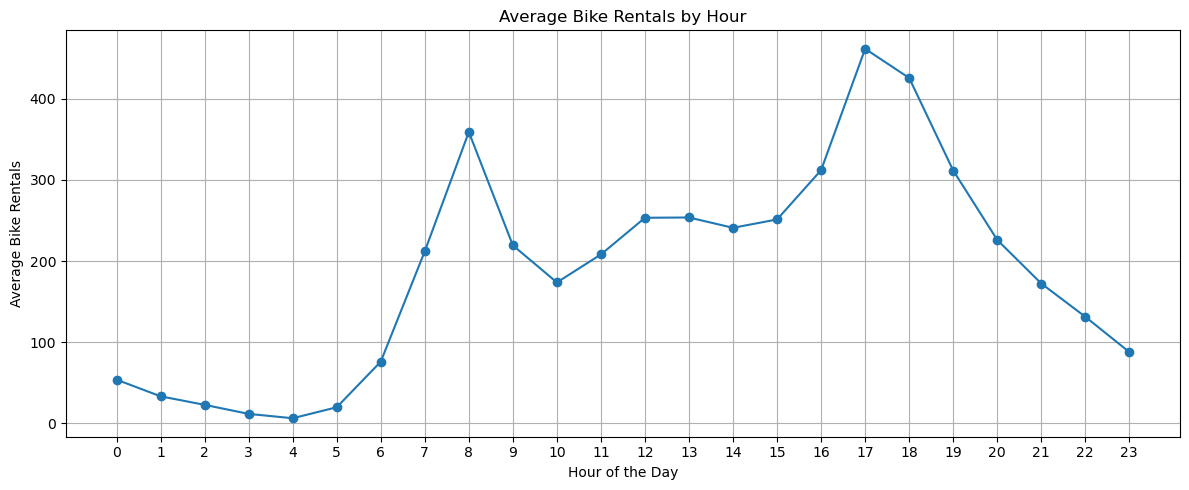

In [28]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(hourly_demand.sort_index().index,
         hourly_demand.sort_index().values,
         marker='o')
plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
season_demand = df.groupby('season')['cnt'].mean()
season_demand.index = ['Spring', 'Summer', 'Fall', 'Winter']
print(season_demand)

Spring    111.114569
Summer    208.344069
Fall      236.016237
Winter    198.868856
Name: cnt, dtype: float64


In [30]:
print("Highest Demand Season:", season_demand.idxmax())
print("Lowest Demand Season:", season_demand.idxmin())

Highest Demand Season: Fall
Lowest Demand Season: Spring


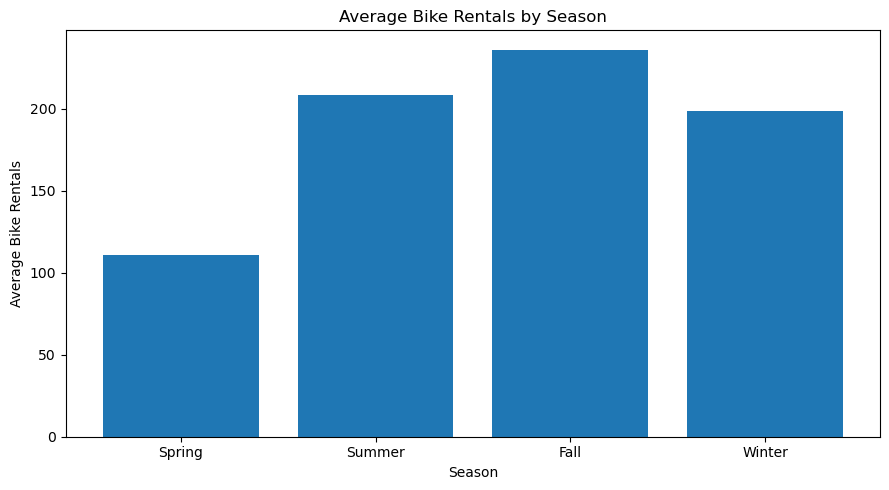

In [31]:
plt.figure(figsize=(9, 5))
plt.bar(season_demand.index, season_demand.values)
plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Bike Rentals')
plt.tight_layout()
plt.show()

In [32]:
monthly_demand = df.groupby('mnth')['cnt'].mean()
print(monthly_demand)

mnth
1      94.424773
2     112.865026
3     155.410726
4     187.260960
5     222.907258
6     240.515278
7     231.819892
8     238.097627
9     240.773138
10    222.158511
11    177.335421
12    142.303439
Name: cnt, dtype: float64


In [33]:
print("Highest Demand Month:", monthly_demand.idxmax())
print("Lowest Demand Month:", monthly_demand.idxmin())

Highest Demand Month: 9
Lowest Demand Month: 1


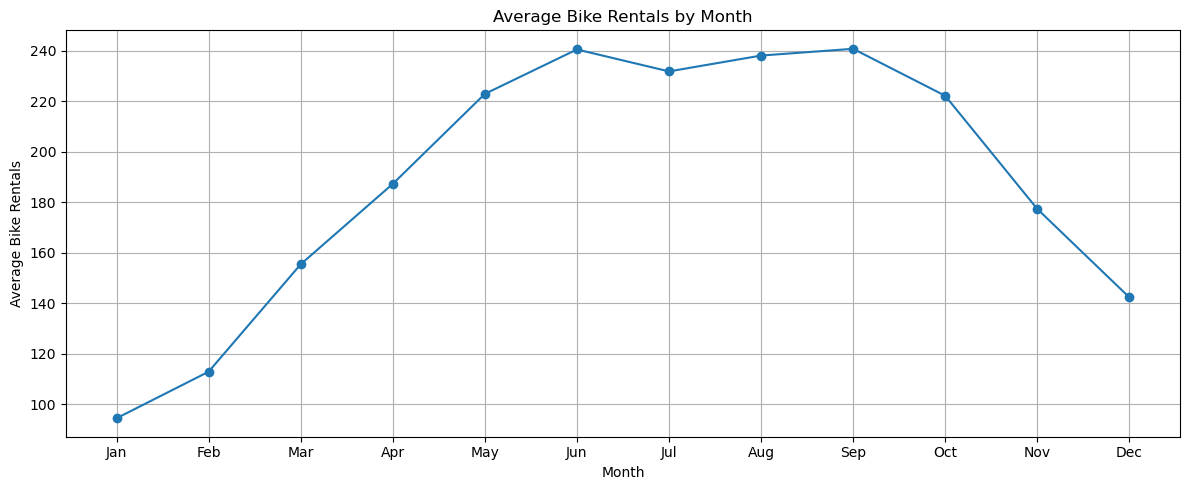

In [34]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(12, 5))
plt.plot(month_names, monthly_demand.values, marker='o')
plt.title('Average Bike Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Bike Rentals')
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
weekday_demand = df.groupby('weekday')['cnt'].mean()
weekday_names = ['Sunday', 'Monday', 'Tuesday', 'Wednesday',
                'Thursday', 'Friday', 'Saturday']
weekday_demand.index = weekday_names
print(weekday_demand)

Sunday       177.468825
Monday       183.744655
Tuesday      191.238891
Wednesday    191.130505
Thursday     196.436665
Friday       196.135907
Saturday     190.209793
Name: cnt, dtype: float64


In [36]:
print("Highest Demand Day:", weekday_demand.idxmax())
print("Lowest Demand Day:", weekday_demand.idxmin())

Highest Demand Day: Thursday
Lowest Demand Day: Sunday


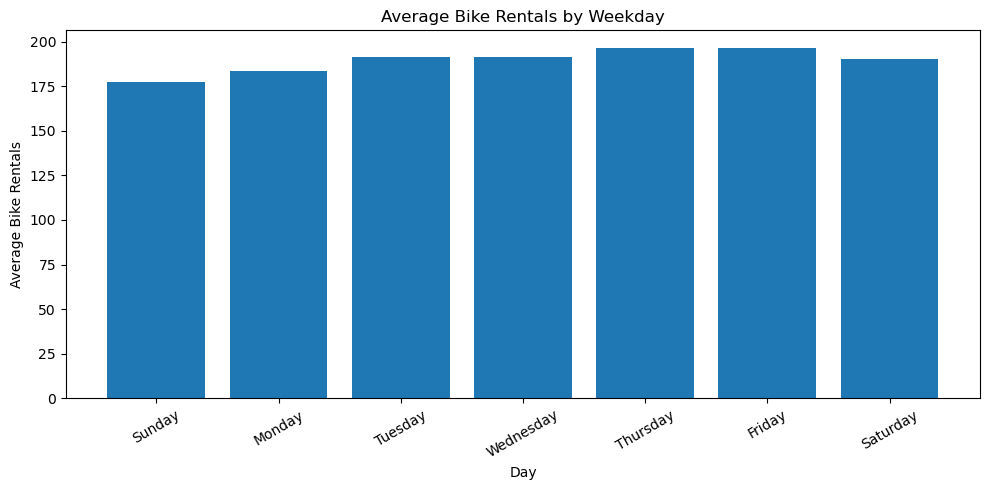

In [37]:
plt.figure(figsize=(10, 5))
plt.bar(weekday_demand.index, weekday_demand.values)
plt.title('Average Bike Rentals by Weekday')
plt.xlabel('Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [38]:
workingday_demand = df.groupby('workingday')['cnt'].mean()
workingday_demand.index = ['Non-Working Day', 'Working Day']
print(workingday_demand)

Non-Working Day    181.405332
Working Day        193.207754
Name: cnt, dtype: float64


In [39]:
print("Higher Demand:", workingday_demand.idxmax())

Higher Demand: Working Day


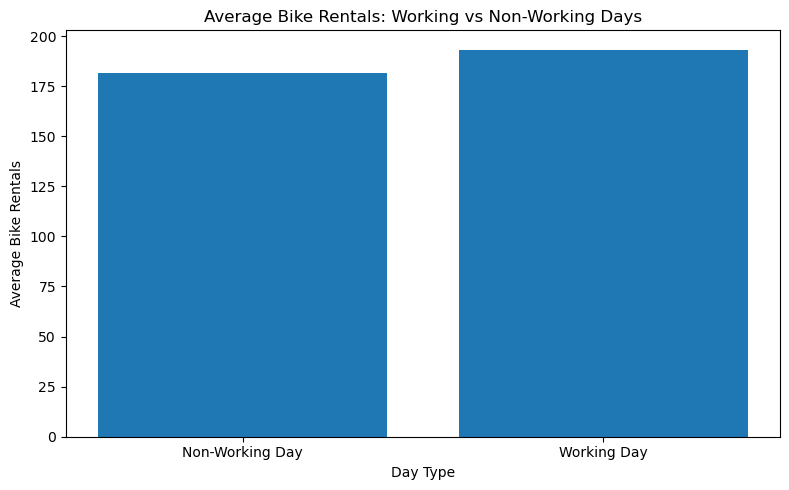

In [40]:
plt.figure(figsize=(8, 5))
plt.bar(workingday_demand.index, workingday_demand.values)
plt.title('Average Bike Rentals: Working vs Non-Working Days')
plt.xlabel('Day Type')
plt.ylabel('Average Bike Rentals')
plt.tight_layout()
plt.show()

In [41]:
weather_demand = df.groupby('weathersit')['cnt'].mean()
print(weather_demand)

weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64


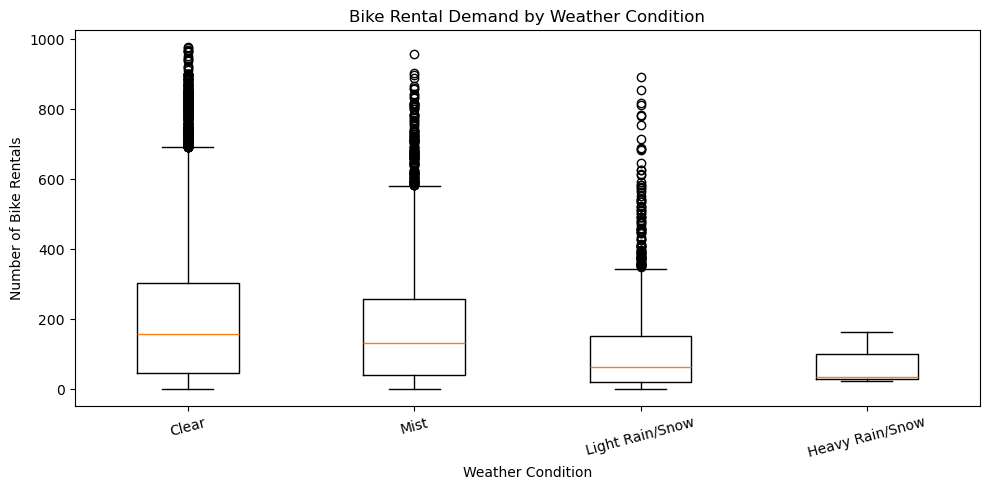

In [42]:
plt.figure(figsize=(10, 5))
plt.boxplot(
    [df[df['weathersit'] == i]['cnt'] for i in [1, 2, 3, 4]],
    tick_labels=['Clear', 'Mist', 'Light Rain/Snow', 'Heavy Rain/Snow']
)
plt.title('Bike Rental Demand by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Number of Bike Rentals')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

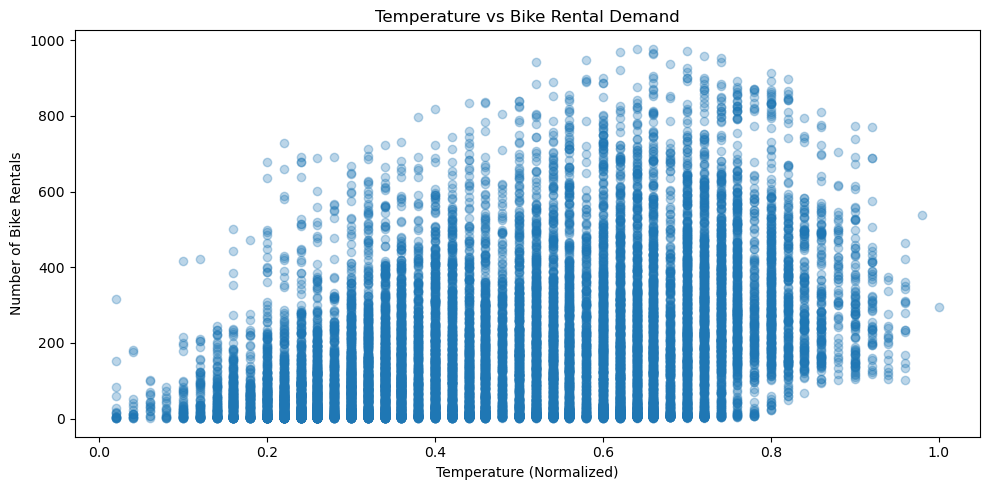

In [43]:
plt.figure(figsize=(10, 5))
plt.scatter(df['temp'], df['cnt'], alpha=0.3)
plt.title('Temperature vs Bike Rental Demand')
plt.xlabel('Temperature (Normalized)')
plt.ylabel('Number of Bike Rentals')
plt.tight_layout()
plt.show()

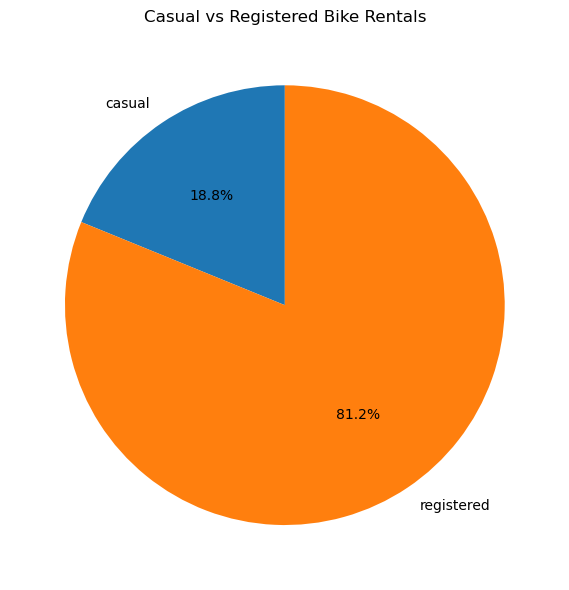

In [44]:
user_types = df[['casual', 'registered']].sum()
plt.figure(figsize=(8, 6))
plt.pie(
    user_types.values,
    labels=user_types.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Casual vs Registered Bike Rentals')
plt.tight_layout()
plt.show()

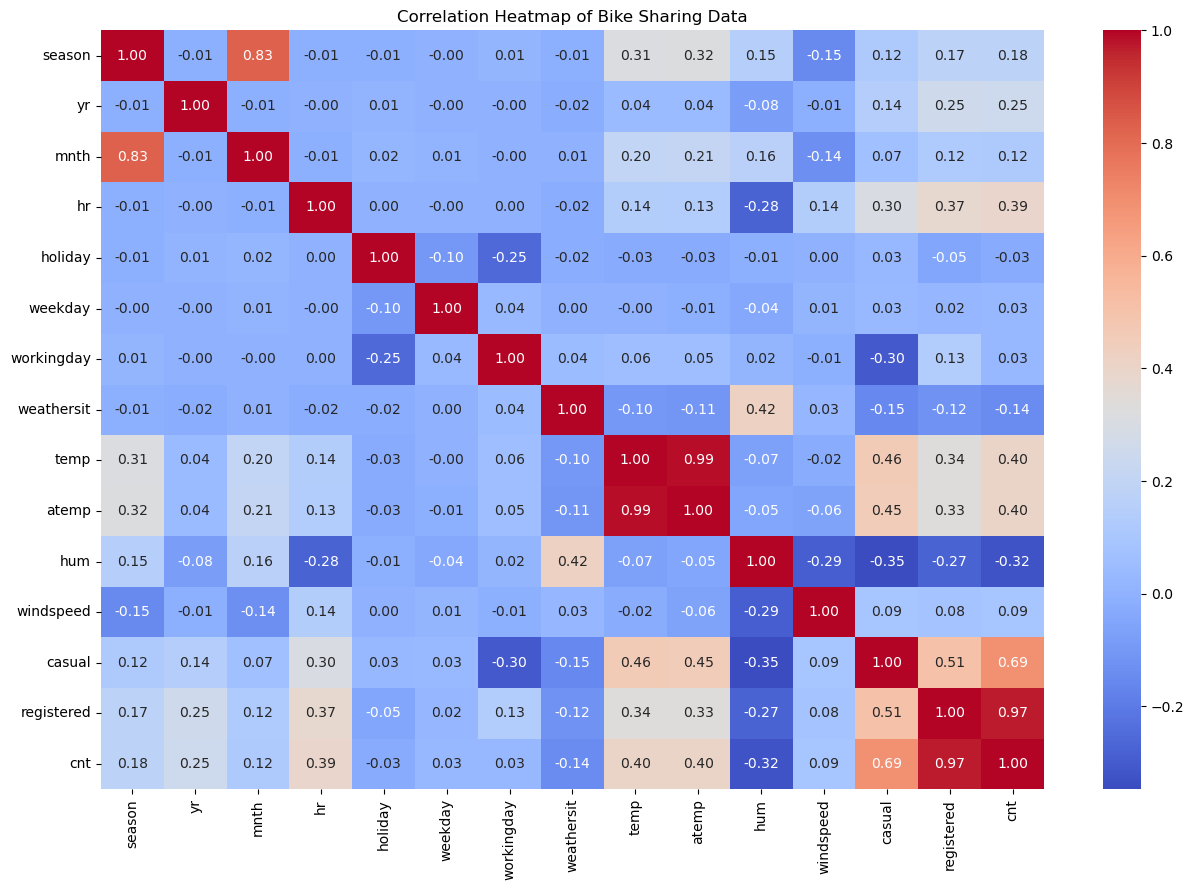

In [45]:
import seaborn as sns
correlation = df.select_dtypes(include='number').drop(columns=['instant']).corr()
plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of Bike Sharing Data')
plt.tight_layout()
plt.show()

In [46]:
correlation['cnt'].sort_values(ascending=False)

cnt           1.000000
registered    0.972151
casual        0.694564
temp          0.404772
atemp         0.400929
hr            0.394071
yr            0.250495
season        0.178056
mnth          0.120638
windspeed     0.093234
workingday    0.030284
weekday       0.026900
holiday      -0.030927
weathersit   -0.142426
hum          -0.322911
Name: cnt, dtype: float64

## Business Insights

1. **Hourly Demand:** Bike rentals are highest at 5 PM (17:00), with an average of approximately 461 rentals. The lowest demand occurs at 4 AM.

2. **Seasonal Demand:** Fall has the highest average rental demand (236), while Spring has the lowest (111).

3. **Monthly Demand:** September has the highest average demand (240.77), while January has the lowest (94.42).

4. **Weekday Demand:** Thursday has the highest average demand, while Sunday has the lowest.

5. **Working Days:** Average bike rentals are higher on working days (193.21) than on non-working days (181.41).

6. **Weather Impact:** The box plot helps compare rental demand across weather conditions.

7. **Temperature:** Temperature has a moderate positive correlation with bike rental demand (0.405).

8. **User Analysis:** Registered users contribute approximately 81.17% of total bike rentals, while casual users contribute 18.83%.

9. **Correlation Analysis:** Humidity has a negative correlation (-0.323) with bike rental demand.

## Conclusion

This project analysed 17,379 hourly bike-sharing records using Python. The analysis identified patterns in rental demand based on time, season, month, weekdays, working days, weather and temperature.

The findings show that bike rental demand varies throughout the day and year. Registered users contribute the majority of rentals, and evening hours experience particularly high demand.

This analysis can help bike-sharing businesses understand customer behaviour and make better operational and resource-planning decisions.